# Telco Customer Churn: Analysis & Prediction

**Author:** Manav Ramchand Novlani

A telecom company loses about 1 in 4 customers. Keeping an existing customer is far cheaper than winning a new one, so the business needs to know **who is likely to leave and why**, early enough to act.

This notebook:
1. Cleans and explores the [IBM Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (7,043 customers, 21 columns)
2. Finds the customer and service traits most linked to churn
3. Trains and tunes four classifiers (Logistic Regression, Decision Tree, Random Forest, SVM)
4. Picks a final model and saves it for the companion Streamlit app (`app.py`)

Because a missed churner costs more than a wasted retention offer, models are judged mainly on **recall and F1 for the churn class**, not plain accuracy.

## 1. Setup

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
DATA_PATH = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
MODEL_DIR = Path("../models")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", 30)

## 2. Load and inspect the data

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 7,043   Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Data quality checks
No column has nulls and there are no duplicate rows, but `TotalCharges` is stored as text. Converting it reveals 11 blank values.

In [4]:
blank_total = raw["TotalCharges"].str.strip().eq("")
print("Missing values per column:", int(raw.isna().sum().sum()))
print("Duplicate rows:          ", int(raw.duplicated().sum()))
print("Blank TotalCharges:      ", int(blank_total.sum()))
raw.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing values per column: 0
Duplicate rows:           0
Blank TotalCharges:       11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 blanks are brand-new customers (`tenure = 0`) who haven't been billed yet, so a total of **$0** is the correct value rather than a missing one. Keeping them (instead of dropping them) also keeps every customer in the analysis.

In [5]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 3. Exploratory data analysis

A small helper keeps every churn-rate calculation consistent.

In [6]:
def churn_rate(data: pd.DataFrame, column: str) -> pd.DataFrame:
    """Churn rate (%) and customer count for each value of `column`, highest rate first."""
    return (
        data.groupby(column, observed=True)["ChurnFlag"]
        .agg(churn_rate="mean", customers="size")
        .assign(churn_rate=lambda t: (t["churn_rate"] * 100).round(1))
        .sort_values("churn_rate", ascending=False)
    )


def plot_churn_rate(data: pd.DataFrame, column: str, ax=None, title=None):
    table = churn_rate(data, column)
    ax = ax or plt.gca()
    sns.barplot(x=table.index.astype(str), y=table["churn_rate"], ax=ax, color="#4C72B0")
    ax.axhline(data["ChurnFlag"].mean() * 100, ls="--", c="grey", lw=1, label="Overall rate")
    ax.set(title=title or f"Churn rate by {column}", xlabel="", ylabel="Churn rate (%)")
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():.0f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.tick_params(axis="x", rotation=15)
    return ax

### 3.1 How many customers churn?

       customers  share_%
Churn                    
No          5174     73.5
Yes         1869     26.5


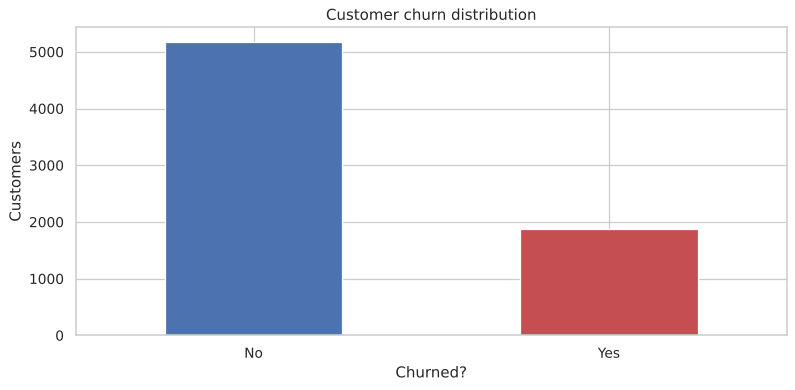

In [7]:
counts = df["Churn"].value_counts()
print(pd.DataFrame({"customers": counts, "share_%": (counts / len(df) * 100).round(1)}))

ax = counts.plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0)
ax.set(title="Customer churn distribution", xlabel="Churned?", ylabel="Customers")
plt.tight_layout()
plt.show()

About **26.5%** of customers churned. The classes are imbalanced (roughly 3:1), which is why accuracy alone would be misleading: a model that always says "No" scores 73%.

### 3.2 Contract, tenure and charges

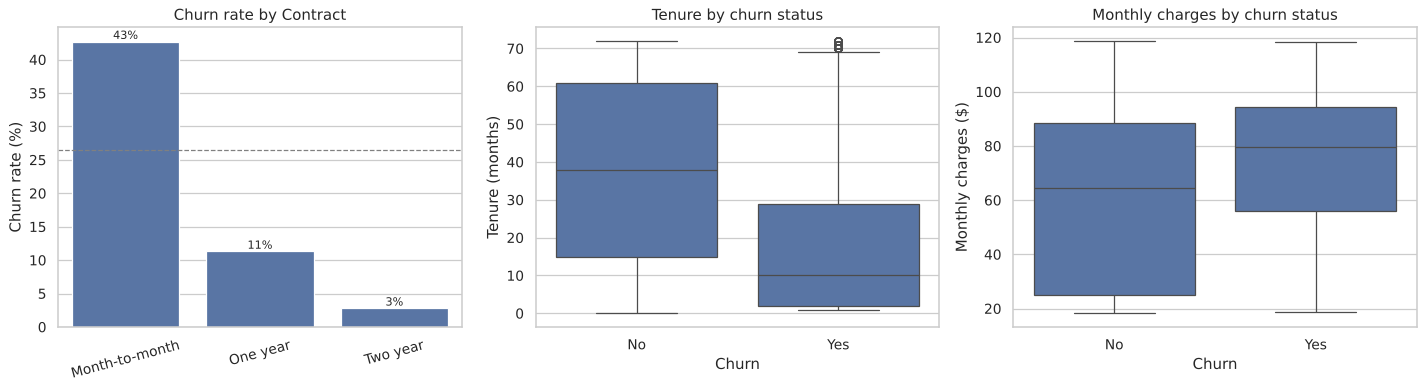

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_churn_rate(df, "Contract", ax=axes[0])
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1])
axes[1].set(title="Tenure by churn status", ylabel="Tenure (months)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2])
axes[2].set(title="Monthly charges by churn status", ylabel="Monthly charges ($)")
plt.tight_layout()
plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median()

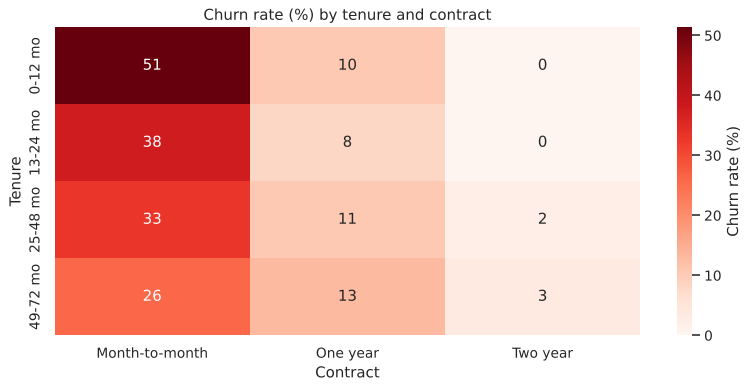

In [9]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])

pivot = df.pivot_table(index="TenureGroup", columns="Contract", values="ChurnFlag",
                       aggfunc="mean", observed=False) * 100
ax = sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"})
ax.set(title="Churn rate (%) by tenure and contract", xlabel="Contract", ylabel="Tenure")
plt.tight_layout()
plt.show()

### 3.3 Services and billing

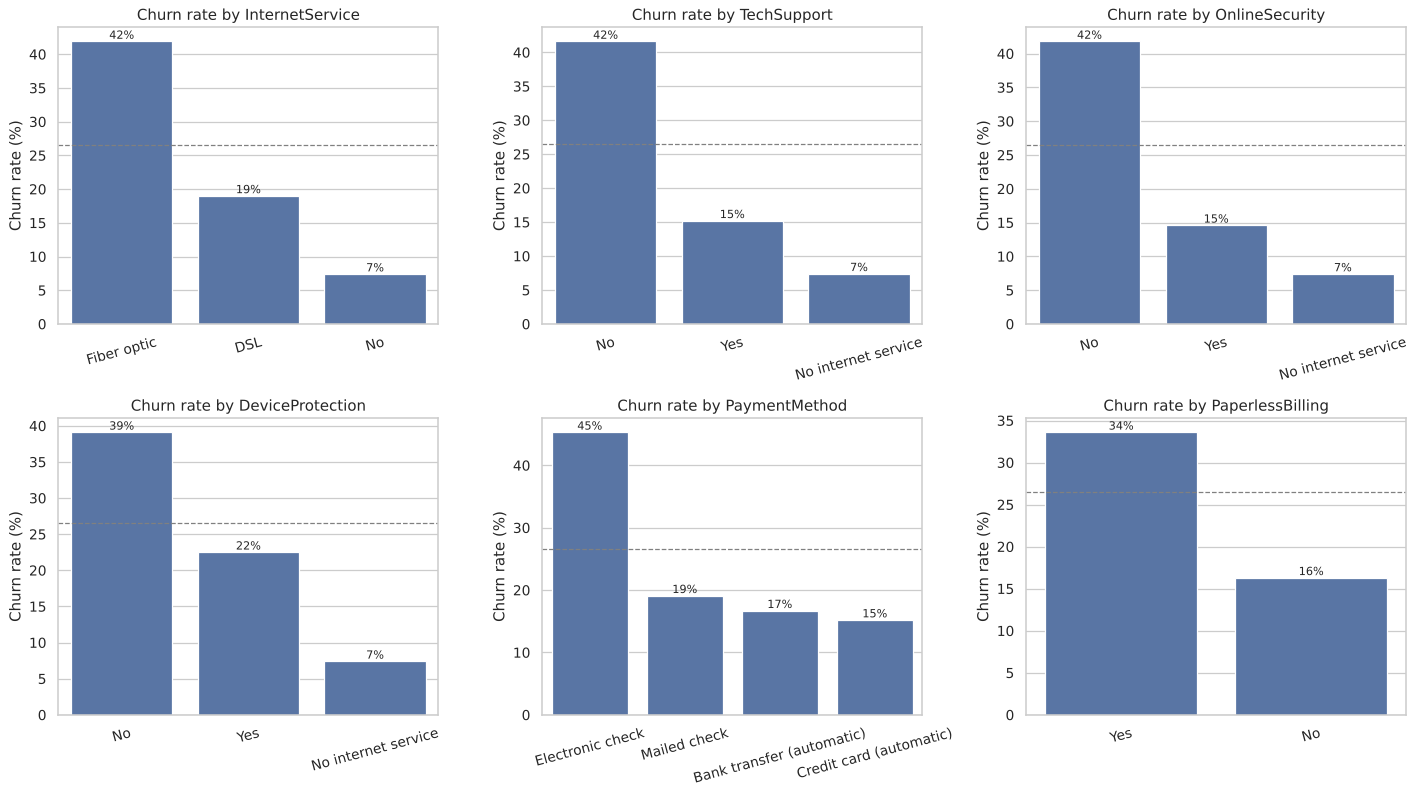

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["InternetService", "TechSupport", "OnlineSecurity",
                               "DeviceProtection", "PaymentMethod", "PaperlessBilling"]):
    plot_churn_rate(df, col, ax=ax)
plt.tight_layout()
plt.show()

### 3.4 Demographics

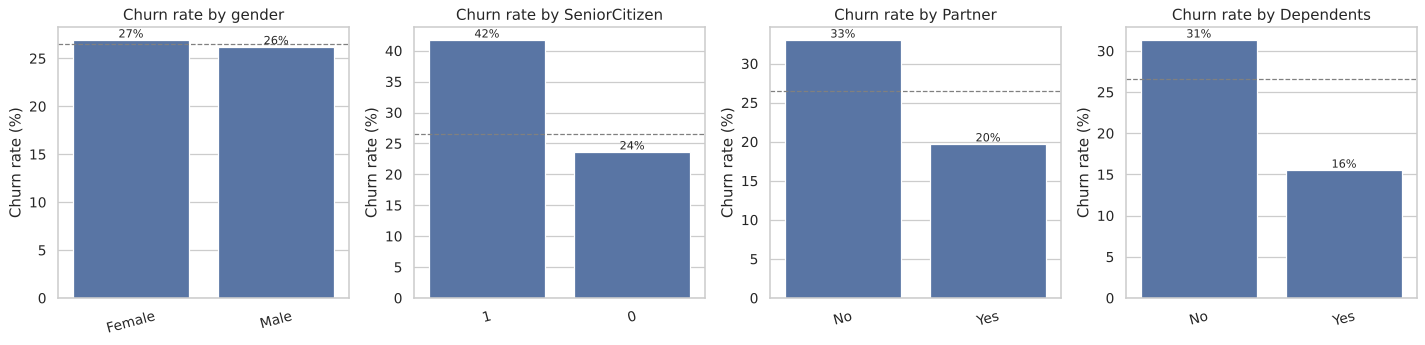

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    plot_churn_rate(df, col, ax=ax)
plt.tight_layout()
plt.show()

### EDA takeaways
- **Contract type is the strongest signal.** Month-to-month customers churn at **42.7%**, against 11.3% on one-year and 2.8% on two-year contracts.
- **The first year is the danger zone.** Churners have a median tenure of 10 months vs 38 for customers who stay. New month-to-month customers (0-12 months) churn at about **51%**.
- **Higher bills, more churn.** Churners pay a median of about \$80/month vs \$64 for those who stay.
- **Fiber optic customers churn at 41.9%**, more than double DSL (19.0%), which hints at a price or service-quality issue.
- **Protective add-ons are linked to loyalty.** Customers without Tech Support or Online Security churn at about 42%, vs roughly 15% with them.
- **Electronic check payers churn at 45.3%**, about 3x the rate of customers on automatic bank or card payments.
- **Gender makes no difference** (26.9% vs 26.2%). Senior citizens and customers without a partner or dependents churn more.

## 4. Prepare data for modelling

`customerID` is an identifier and the EDA helper columns are dropped. Numeric features are standardised and categorical features one-hot encoded **inside a pipeline**, so the exact same preprocessing is applied at training time and inside the Streamlit app.

In [12]:
TARGET = "ChurnFlag"
X = df.drop(columns=["customerID", "Churn", "ChurnFlag", "TenureGroup"])
y = df[TARGET]

numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in X.columns if c not in numeric_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print(f"Churn share - train: {y_train.mean():.1%}  test: {y_test.mean():.1%}")
print(f"{len(numeric_features)} numeric + {len(categorical_features)} categorical features")

Train: (5634, 19)  Test: (1409, 19)
Churn share - train: 26.5%  test: 26.5%
4 numeric + 15 categorical features


## 5. Baseline models

All four models share the same preprocessing pipeline and are scored on the same held-out test set.

In [13]:
def make_pipeline(classifier) -> Pipeline:
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])


def evaluate(name: str, model, X_eval=X_test, y_eval=y_test) -> dict:
    pred = model.predict(X_eval)
    # SVC has no predict_proba by default; its decision scores work the same for ROC AUC
    scores = (model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba")
              else model.decision_function(X_eval))
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Churn precision": precision_score(y_eval, pred),
        "Churn recall": recall_score(y_eval, pred),
        "Churn F1": f1_score(y_eval, pred),
        "ROC AUC": roc_auc_score(y_eval, scores),
    }


baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": SVC(kernel="rbf", random_state=RANDOM_STATE),
}

baseline_results = []
for name, clf in baseline_models.items():
    pipe = make_pipeline(clf).fit(X_train, y_train)
    baseline_results.append(evaluate(name, pipe))

baseline_table = pd.DataFrame(baseline_results).set_index("Model").sort_values("Churn F1", ascending=False)
baseline_table.round(3)

,Accuracy,Churn precision,Churn recall,Churn F1,ROC AUC
Model,,,,,
Logistic Regression,0.806,0.657,0.559,0.604,0.842
Decision Tree,0.798,0.635,0.567,0.599,0.830
SVM,0.791,0.642,0.484,0.552,0.790
Random Forest,0.784,0.619,0.481,0.541,0.821


Every baseline reaches roughly 79-80% accuracy, but **recall on churners is only around 50%**: half of the customers who actually leave are missed. That is the number to improve.

## 6. Hyperparameter tuning

Each model is tuned with 5-fold stratified cross-validation, optimising **churn F1** (a balance of catching churners and not flooding the retention team with false alarms). The grids include `class_weight="balanced"`, which tells the model to pay more attention to the minority churn class.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"classifier__C": [0.01, 0.1, 1, 10], "classifier__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"classifier__max_depth": [3, 5, 7, 10],
         "classifier__min_samples_leaf": [1, 5, 10, 20],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"classifier__n_estimators": [200],
         "classifier__max_depth": [6, 10, None],
         "classifier__min_samples_leaf": [1, 5, 10],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "SVM": (
        SVC(kernel="rbf", random_state=RANDOM_STATE),
        {"classifier__C": [0.5, 1], "classifier__class_weight": [None, "balanced"]},
    ),
}

tuned_models, tuned_results, cv_scores = {}, [], {}
for name, (clf, grid) in search_spaces.items():
    search = GridSearchCV(make_pipeline(clf), grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    cv_scores[name] = search.best_score_
    best = {k.replace("classifier__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:<20} CV churn F1 = {search.best_score_:.3f}   best params: {best}")
    tuned_results.append(evaluate(f"{name} (tuned)", search.best_estimator_))

Logistic Regression  CV churn F1 = 0.629   best params: {'C': 0.1, 'class_weight': 'balanced'}
Decision Tree        CV churn F1 = 0.619   best params: {'class_weight': 'balanced', 'max_depth': 3, 'min_samples_leaf': 1}
Random Forest        CV churn F1 = 0.635   best params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 10, 'n_estimators': 200}
SVM                  CV churn F1 = 0.624   best params: {'C': 1, 'class_weight': 'balanced'}


## 7. Model comparison

In [15]:
comparison = pd.concat([baseline_table.reset_index(), pd.DataFrame(tuned_results)])
comparison = comparison.set_index("Model").sort_values("Churn F1", ascending=False)
comparison.round(3)

,Accuracy,Churn precision,Churn recall,Churn F1,ROC AUC
Model,,,,,
Random Forest (tuned),0.757,0.527,0.802,0.636,0.843
Decision Tree (tuned),0.746,0.514,0.783,0.621,0.814
Logistic Regression (tuned),0.742,0.509,0.786,0.618,0.841
SVM (tuned),0.744,0.512,0.773,0.616,0.821
Logistic Regression,0.806,0.657,0.559,0.604,0.842
Decision Tree,0.798,0.635,0.567,0.599,0.830
SVM,0.791,0.642,0.484,0.552,0.790
Random Forest,0.784,0.619,0.481,0.541,0.821


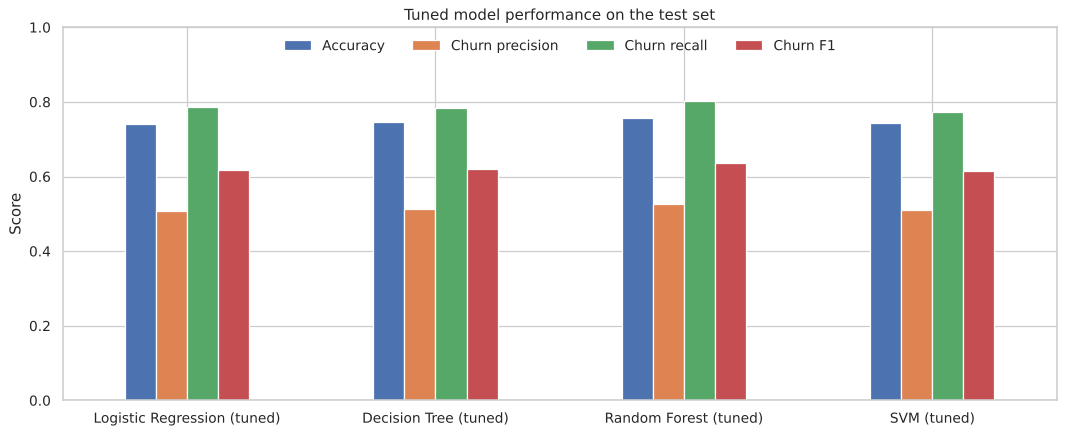

In [16]:
metrics = ["Accuracy", "Churn precision", "Churn recall", "Churn F1"]
ax = comparison.loc[[f"{n} (tuned)" for n in tuned_models], metrics].plot(kind="bar", figsize=(12, 5), rot=0)
ax.set(title="Tuned model performance on the test set", ylabel="Score", ylim=(0, 1), xlabel="")
ax.legend(ncol=4, loc="upper center", frameon=False)
plt.tight_layout()
plt.show()

### Choosing the final model
The final model is chosen by **cross-validated churn F1 on the training data**, not by test-set results, so the test set stays an honest estimate of real-world performance.

Selected model: Random Forest

              precision    recall  f1-score   support

      Stayed       0.91      0.74      0.82      1035
     Churned       0.53      0.80      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



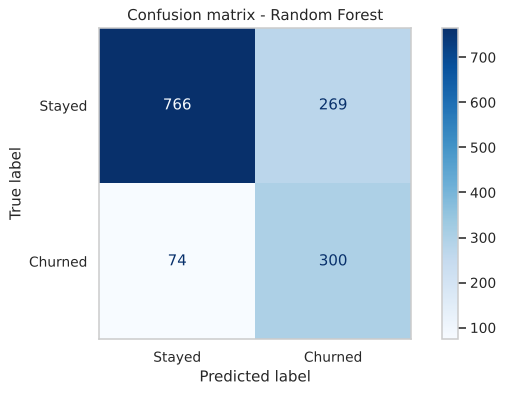

In [17]:
# The app shows a churn probability, so only models that output probabilities are eligible
eligible = {n: score for n, score in cv_scores.items() if hasattr(tuned_models[n], "predict_proba")}
final_name = max(eligible, key=eligible.get)
final_model = tuned_models[final_name]
final_metrics = evaluate(final_name, final_model)

print(f"Selected model: {final_name}\n")
print(classification_report(y_test, final_model.predict(X_test), target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test,
                                      display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title(f"Confusion matrix - {final_name}")
plt.grid(False)
plt.show()

## 8. What drives churn?

Feature importances from the final model show which inputs it relies on most. The tuned Decision Tree is then drawn to show, in plain if/then rules, how those features split customers.

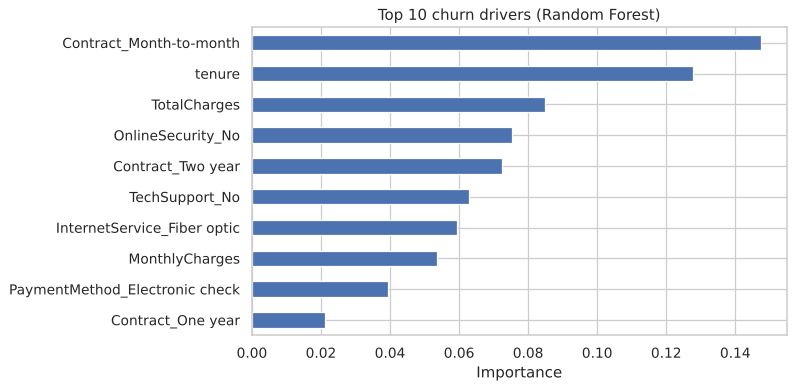

In [18]:
def feature_names_of(pipe):
    return [n.split("__", 1)[1] for n in pipe.named_steps["preprocessor"].get_feature_names_out()]

classifier = final_model.named_steps["classifier"]
if hasattr(classifier, "feature_importances_"):
    weights = classifier.feature_importances_
else:  # linear models: use the size of each coefficient
    weights = np.abs(classifier.coef_[0])
importance = pd.Series(weights, index=feature_names_of(final_model)).sort_values(ascending=False).head(10)

ax = importance.sort_values().plot(kind="barh", color="#4C72B0")
ax.set(title=f"Top 10 churn drivers ({final_name})", xlabel="Importance")
plt.tight_layout()
plt.show()

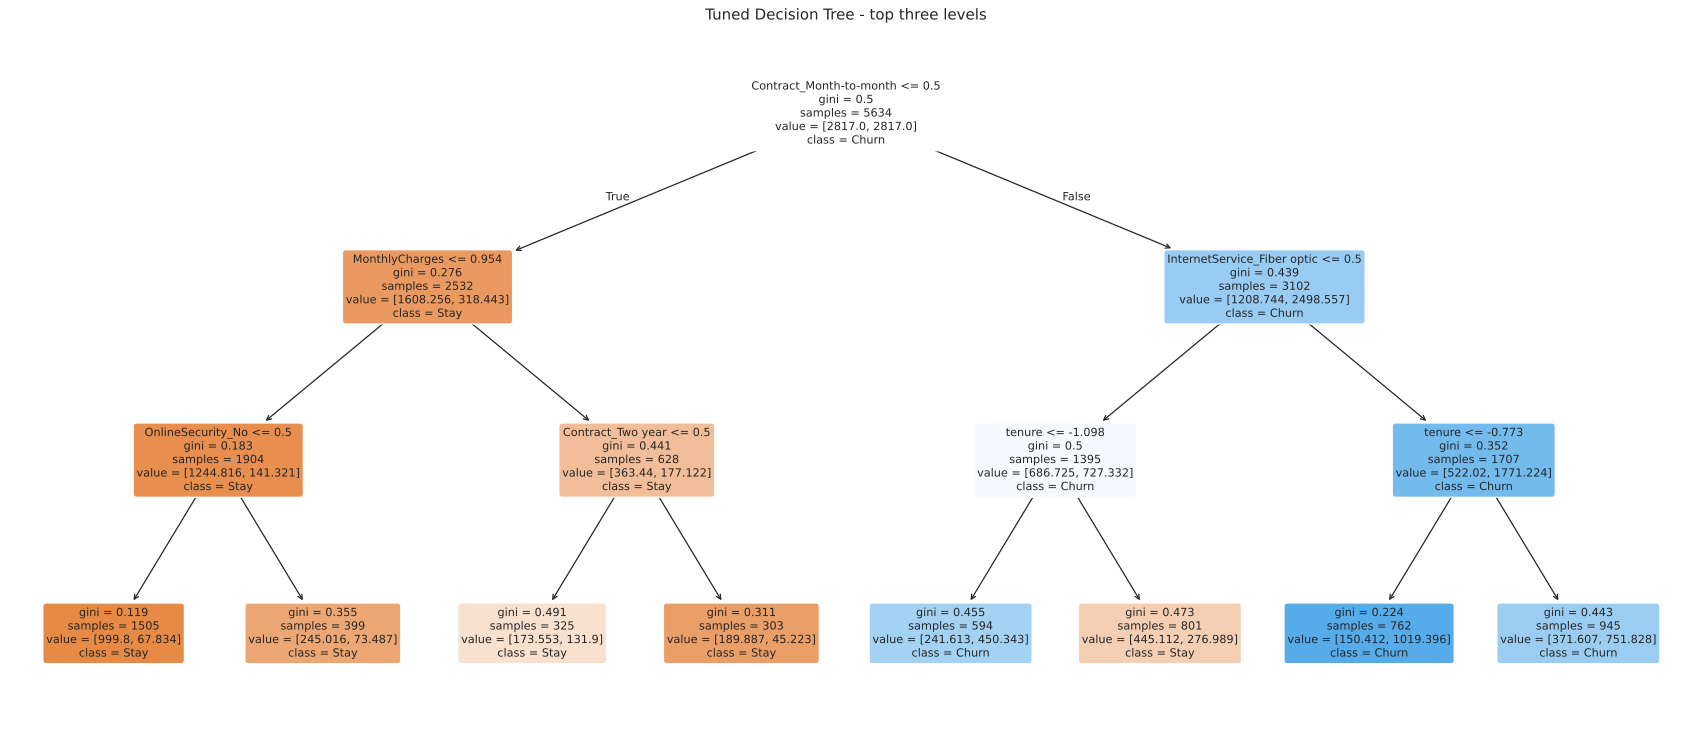

In [19]:
plt.figure(figsize=(24, 10))
tree_pipe = tuned_models["Decision Tree"]
plot_tree(tree_pipe.named_steps["classifier"], feature_names=feature_names_of(tree_pipe),
          class_names=["Stay", "Churn"], filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Tuned Decision Tree - top three levels")
plt.show()

## 9. Save the model for the app

In [20]:
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(final_model, MODEL_DIR / "churn_model.pkl")

summary = {
    "model_name": final_name,
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items() if k != "Model"},
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "features": list(X.columns),
}
(MODEL_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary["test_metrics"], indent=2))

{
  "Accuracy": 0.7566,
  "Churn precision": 0.5272,
  "Churn recall": 0.8021,
  "Churn F1": 0.6363,
  "ROC AUC": 0.8431
}


## 10. Conclusions and recommendations
**Model.** The tuned **Random Forest** (with balanced class weights) catches **80% of churners** on unseen customers, up from about 56% for the best untuned model, with a churn F1 of 0.64 and ROC AUC of 0.84. Accuracy drops from about 81% to 76% because the model now flags more customers who end up staying. For a retention campaign that's usually a good trade: a discount offered to a loyal customer costs less than losing one who was about to leave.

**Who is at risk.** New customers on month-to-month contracts, especially fiber optic users paying by electronic check without tech support or online security.

**Recommended actions**
1. **Contract upgrades:** offer a discount or perk for moving month-to-month customers onto one- or two-year plans, ideally within their first few months.
2. **Early-life onboarding:** give extra attention in the first 12 months, when churn is highest.
3. **Bundle protection services:** include Tech Support / Online Security free or discounted for at-risk customers.
4. **Autopay incentives:** nudge electronic check users towards automatic payments.
5. **Review the fiber offer:** the high fiber churn rate suggests checking its pricing and reliability.

**Limitations and next steps.** This is a single snapshot with no reasons for leaving, customer-service history or competitor pricing. Next steps could include gradient boosting models, tuning the decision threshold to a retention budget, and estimating the revenue saved per correctly flagged customer.